In [1]:
import os
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

In [2]:
HOME = os.path.expanduser("~")
HPC_ROOT = os.path.join(HOME, "irp-efs25")
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
ROOT = HPC_ROOT if os.path.exists(HPC_ROOT) else REPO_ROOT

DATA_ROOT = os.path.join(ROOT, "data")
PROCESSED_DATA_DIR = os.path.join(DATA_ROOT, "processed")
CMIP6_LOAD_DIR = os.path.join(PROCESSED_DATA_DIR, "cmip6")
SATELLITE_PATH = os.path.join(PROCESSED_DATA_DIR, "satellite", "satellite_covariates_1deg_1970_2024.zarr",)

CMIP6_MODELS = [
    "CESM2",
    "CanESM5",
    "CanESM5-CanOE",
    "GFDL-ESM4",
    "UKESM1-0-LL",
]

VARIABLES = {
    "chlos": {
        "label": "Chlorophyll-a",
        "units": "mg m$^{-3}$",
        "floor": 1e-6,
    },
    "mlotst": {
        "label": "Mixed-layer depth",
        "units": "m",
        "floor": 1e-3,
    },
}

print("Root:", ROOT)
print("Satellite path:", SATELLITE_PATH)
print("CMIP6 directory:", CMIP6_LOAD_DIR)

Root: /rds/general/user/efs25/home/irp-efs25
Satellite path: /rds/general/user/efs25/home/irp-efs25/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
CMIP6 directory: /rds/general/user/efs25/home/irp-efs25/data/processed/cmip6


helpers

In [3]:
def finite_values(da):
    values = np.asarray(da.values, dtype=np.float64).ravel()
    return values[np.isfinite(values)]


def distribution_summary(da, source, variable, floor):
    values = finite_values(da)
    positive = values[values > 0]
    logged = np.log10(np.clip(positive, floor, None))

    def q(arr, p):
        return float(np.percentile(arr, p)) if arr.size else np.nan

    return {
        "source": source,
        "variable": variable,
        "n_finite": int(values.size),
        "n_nonpositive": int((values <= 0).sum()),
        "fraction_nonpositive": float((values <= 0).mean()) if values.size else np.nan,
        "raw_min": float(values.min()) if values.size else np.nan,
        "raw_p01": q(values, 1),
        "raw_p05": q(values, 5),
        "raw_median": q(values, 50),
        "raw_mean": float(values.mean()) if values.size else np.nan,
        "raw_p95": q(values, 95),
        "raw_p99": q(values, 99),
        "raw_max": float(values.max()) if values.size else np.nan,
        "raw_mean_median_ratio": float(values.mean() / np.median(values)) if values.size and np.median(values) != 0 else np.nan,
        "log_p01": q(logged, 1),
        "log_p05": q(logged, 5),
        "log_median": q(logged, 50),
        "log_mean": float(logged.mean()) if logged.size else np.nan,
        "log_p95": q(logged, 95),
        "log_p99": q(logged, 99),
        "log_min": float(logged.min()) if logged.size else np.nan,
        "log_max": float(logged.max()) if logged.size else np.nan,
        "log_std": float(logged.std()) if logged.size else np.nan,
    }


def plot_raw_log(da, source, variable, floor, label, units):
    values = finite_values(da)
    positive = values[values > 0]
    logged = np.log10(np.clip(positive, floor, None))

    raw_lo, raw_hi = np.percentile(positive, [0.1, 99.9])
    log_lo, log_hi = np.percentile(logged, [0.1, 99.9])

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].hist(positive, bins=160, range=(raw_lo, raw_hi), color="tab:blue")
    axes[0].set_title(f"{source}: raw {label}")
    axes[0].set_xlabel(units)
    axes[0].set_ylabel("Count")
    axes[0].grid(alpha=0.25)

    axes[1].hist(logged, bins=160, range=(log_lo, log_hi), color="tab:orange")
    axes[1].set_title(f"{source}: log10 {label}")
    axes[1].set_xlabel(f"log10({units})")
    axes[1].set_ylabel("Count")
    axes[1].grid(alpha=0.25)

    fig.suptitle(
        f"{label}: floor={floor:g}; non-positive values={int((values <= 0).sum()):,}",
        y=1.03,
    )
    plt.tight_layout()
    plt.show()


def monthly_climatology_summary(da, floor):
    log_da = np.log10(da.clip(min=floor))
    clim = log_da.groupby("time.month").mean("time")
    anom = log_da.groupby("time.month") - clim

    raw_anom = da.groupby("time.month") - da.groupby("time.month").mean("time")

    log_anom_values = finite_values(anom)
    raw_anom_values = finite_values(raw_anom)

    return {
        "raw_anomaly_p01": float(np.percentile(raw_anom_values, 1)),
        "raw_anomaly_p99": float(np.percentile(raw_anom_values, 99)),
        "log_anomaly_p01": float(np.percentile(log_anom_values, 1)),
        "log_anomaly_p99": float(np.percentile(log_anom_values, 99)),
        "log_anomaly_mean": float(log_anom_values.mean()),
        "log_anomaly_std": float(log_anom_values.std()),
    }


satellite

Satellite dimensions: {'time': 660, 'lat': 180, 'lon': 360}
Satellite time range: 1970-01-01 to 2024-12-01
Satellite variables: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'sos', 'sos_anom', 'tos', 'tos_anom']


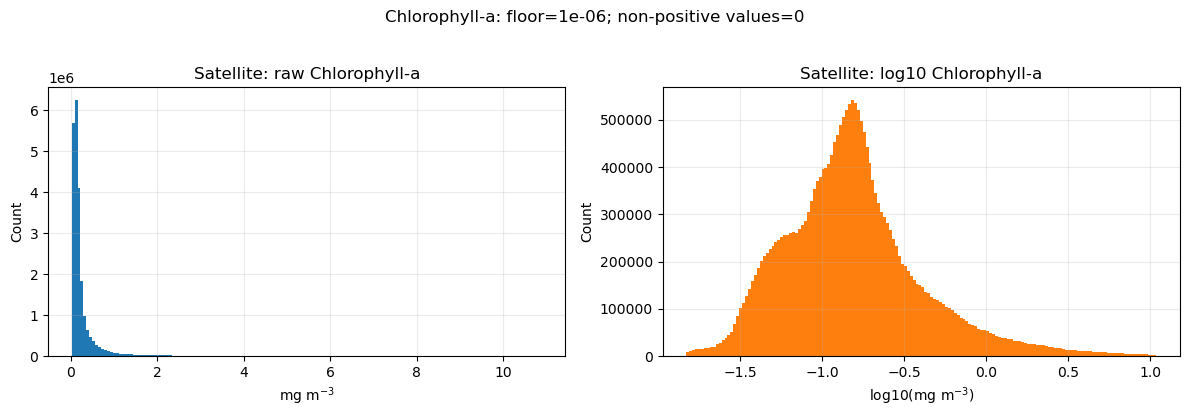

raw_anomaly_p01    -4.413007e-01
raw_anomaly_p99     4.455279e-01
log_anomaly_p01    -3.115890e-01
log_anomaly_p99     2.881738e-01
log_anomaly_mean   -1.024886e-10
log_anomaly_std     9.437359e-02
dtype: float64


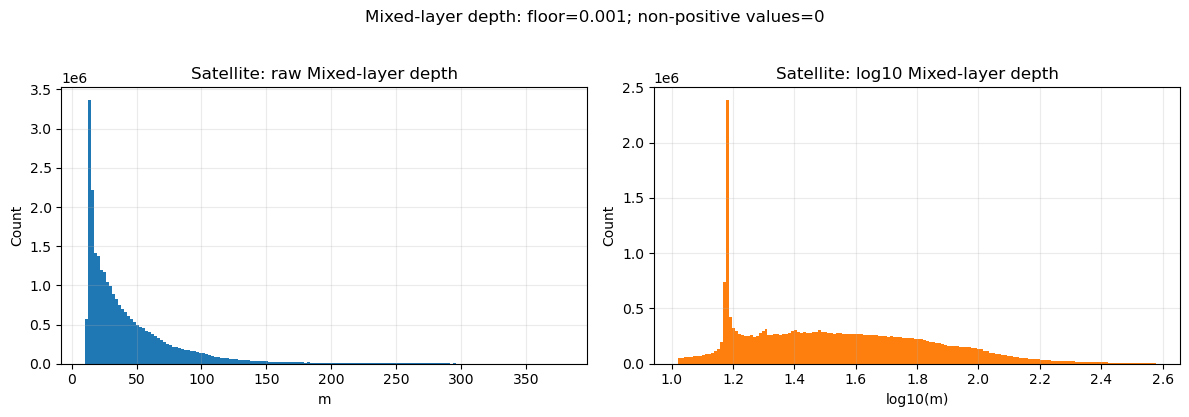

raw_anomaly_p01    -3.325067e+01
raw_anomaly_p99     3.532252e+01
log_anomaly_p01    -2.229094e-01
log_anomaly_p99     2.142053e-01
log_anomaly_mean   -1.170661e-17
log_anomaly_std     6.972634e-02
dtype: float64

Satellite summary


,source,variable,n_finite,n_nonpositive,fraction_nonpositive,raw_min,raw_p01,raw_p05,raw_median,raw_mean,...,raw_mean_median_ratio,log_p01,log_p05,log_median,log_mean,log_p95,log_p99,log_min,log_max,log_std
0,Satellite,chlos,22483817,0,0.0,0.01094,0.024262,0.037708,0.142795,0.305152,...,2.136987,-1.615082,-1.423570,-0.845286,-0.813189,-0.022347,0.523862,-1.960967,1.730559,0.425666
1,Satellite,mlotst,27218462,0,0.0,10.10000,11.549979,14.700000,31.799543,45.478745,...,1.430170,1.062581,1.167317,1.502421,1.536924,2.076280,2.335505,1.004321,3.320566,0.307191


In [4]:
assert os.path.exists(SATELLITE_PATH), f"Not found: {SATELLITE_PATH}"
ds_sat = xr.open_zarr(SATELLITE_PATH, chunks=None)

print("Satellite dimensions:", dict(ds_sat.sizes))
print("Satellite time range:", str(ds_sat.time.values[0])[:10], "to", str(ds_sat.time.values[-1])[:10])
print("Satellite variables:", list(ds_sat.data_vars))

rows = []
for variable, meta in VARIABLES.items():
    assert variable in ds_sat, f"Satellite variable missing: {variable}"
    da = ds_sat[variable].load()
    rows.append(distribution_summary(da, "Satellite", variable, meta["floor"]))
    plot_raw_log(da, "Satellite", variable, meta["floor"], meta["label"], meta["units"])
    print(pd.Series(monthly_climatology_summary(da, meta["floor"])))
    del da
    gc.collect()

satellite_summary = pd.DataFrame(rows)
print("\nSatellite summary")
display(satellite_summary)

cmip6


Loading CESM2
Dimensions: {'time': 3012, 'lat': 180, 'lon': 360}
Time range: 1850-01-15 to 2100-12-15


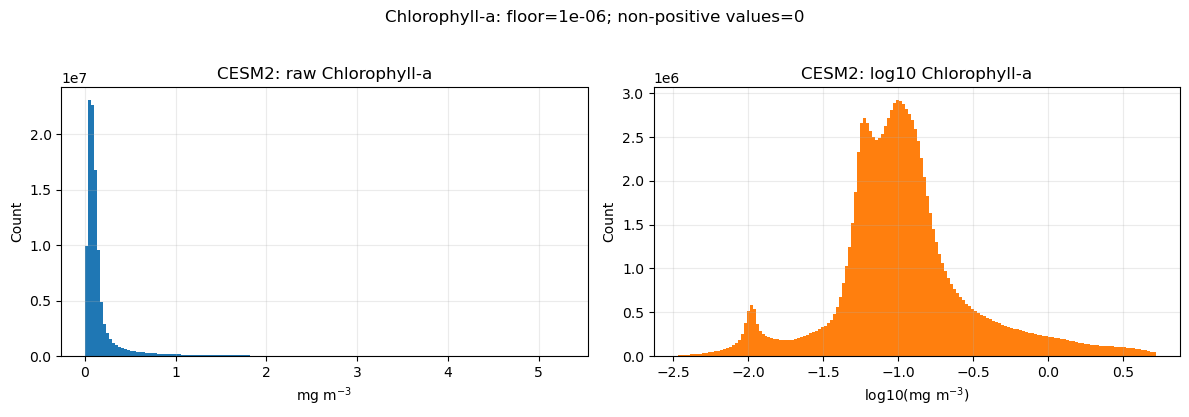


CESM2: chlos anomaly comparison


raw_anomaly_p01    -7.465953e-01
raw_anomaly_p99     9.810486e-01
log_anomaly_p01    -4.775215e-01
log_anomaly_p99     5.162766e-01
log_anomaly_mean   -6.640833e-10
log_anomaly_std     1.587702e-01
dtype: float64


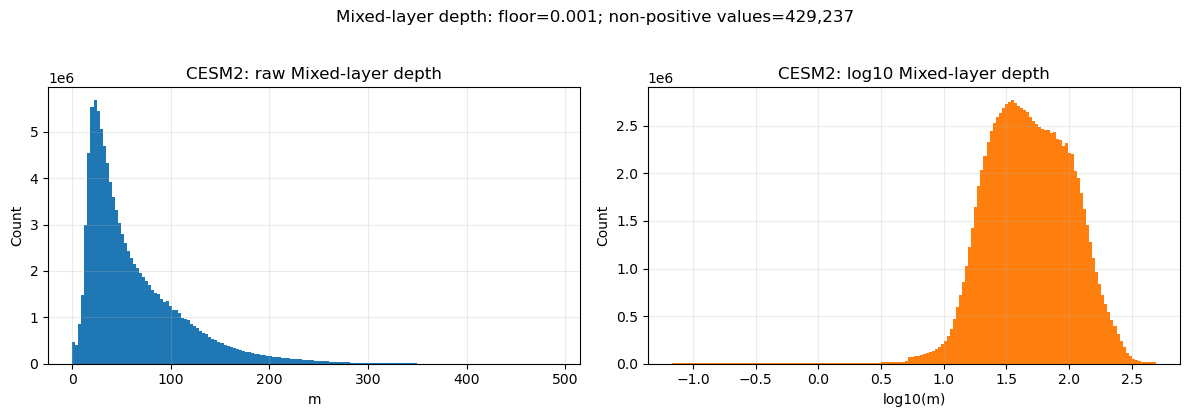


CESM2: mlotst anomaly comparison


raw_anomaly_p01    -4.264937e+01
raw_anomaly_p99     4.470445e+01
log_anomaly_p01    -3.030714e-01
log_anomaly_p99     2.857752e-01
log_anomaly_mean   -1.585703e-10
log_anomaly_std     1.724092e-01
dtype: float64

Loading CanESM5
Dimensions: {'time': 3012, 'lat': 180, 'lon': 360}
Time range: 1850-01-16 to 2100-12-16


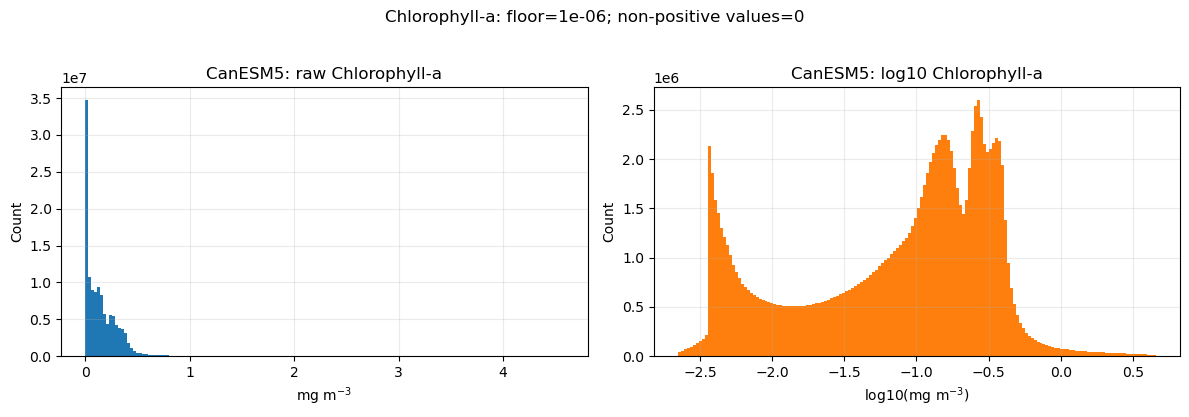


CanESM5: chlos anomaly comparison


raw_anomaly_p01    -3.036540e-01
raw_anomaly_p99     3.750533e-01
log_anomaly_p01    -7.379897e-01
log_anomaly_p99     7.254957e-01
log_anomaly_mean   -2.146317e-10
log_anomaly_std     2.173425e-01
dtype: float64


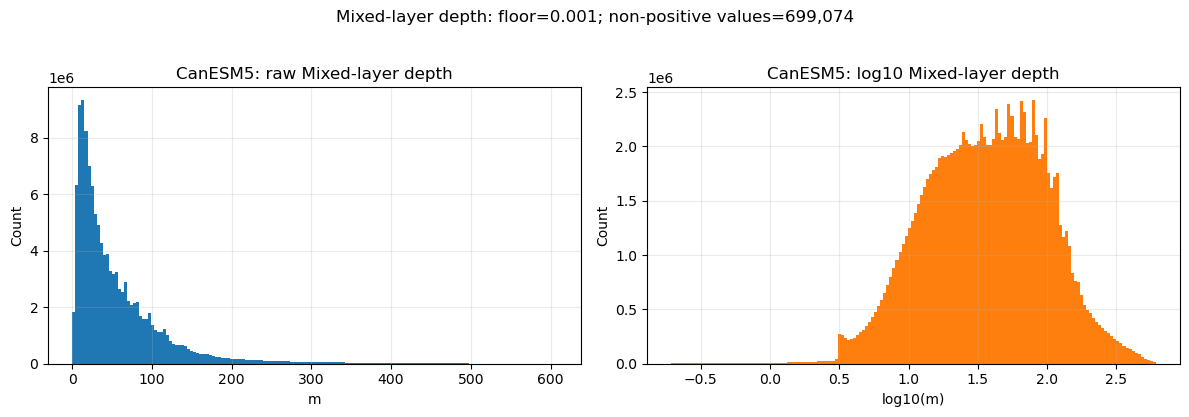


CanESM5: mlotst anomaly comparison


raw_anomaly_p01    -7.134817e+01
raw_anomaly_p99     7.785029e+01
log_anomaly_p01    -4.469871e-01
log_anomaly_p99     5.007846e-01
log_anomaly_mean    1.246816e-10
log_anomaly_std     2.451587e-01
dtype: float64

Loading CanESM5-CanOE
Dimensions: {'time': 3012, 'lat': 180, 'lon': 360}
Time range: 1850-01-16 to 2100-12-16


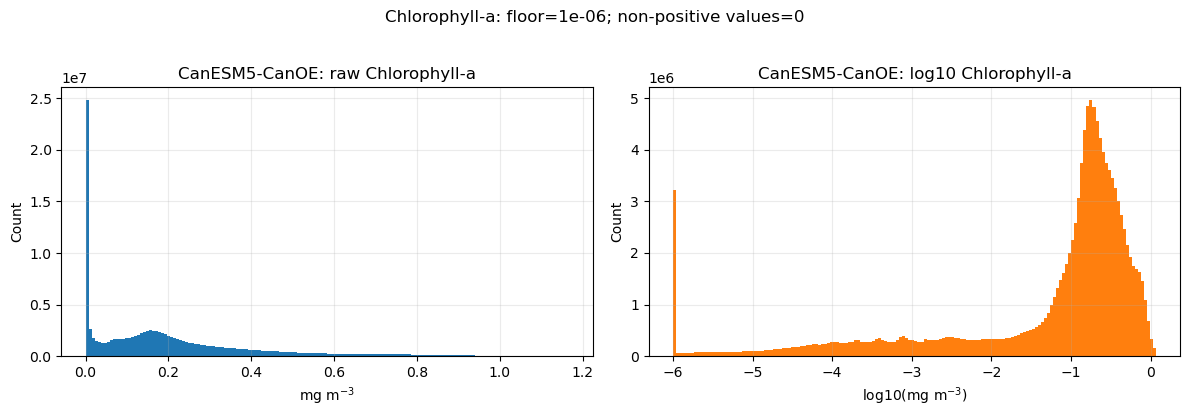


CanESM5-CanOE: chlos anomaly comparison


raw_anomaly_p01    -1.904093e-01
raw_anomaly_p99     2.323300e-01
log_anomaly_p01    -1.711263e+00
log_anomaly_p99     1.942705e+00
log_anomaly_mean    1.258322e-10
log_anomaly_std     4.945384e-01
dtype: float64


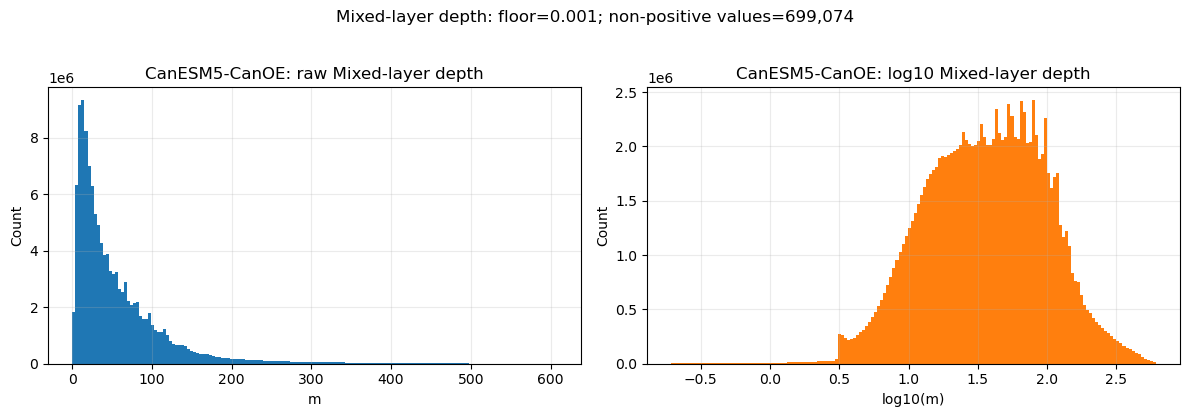


CanESM5-CanOE: mlotst anomaly comparison


raw_anomaly_p01    -7.134817e+01
raw_anomaly_p99     7.785029e+01
log_anomaly_p01    -4.469871e-01
log_anomaly_p99     5.007846e-01
log_anomaly_mean    1.246816e-10
log_anomaly_std     2.451587e-01
dtype: float64

Loading GFDL-ESM4
Dimensions: {'time': 3012, 'lat': 180, 'lon': 360}
Time range: 1850-01-16 to 2100-12-16


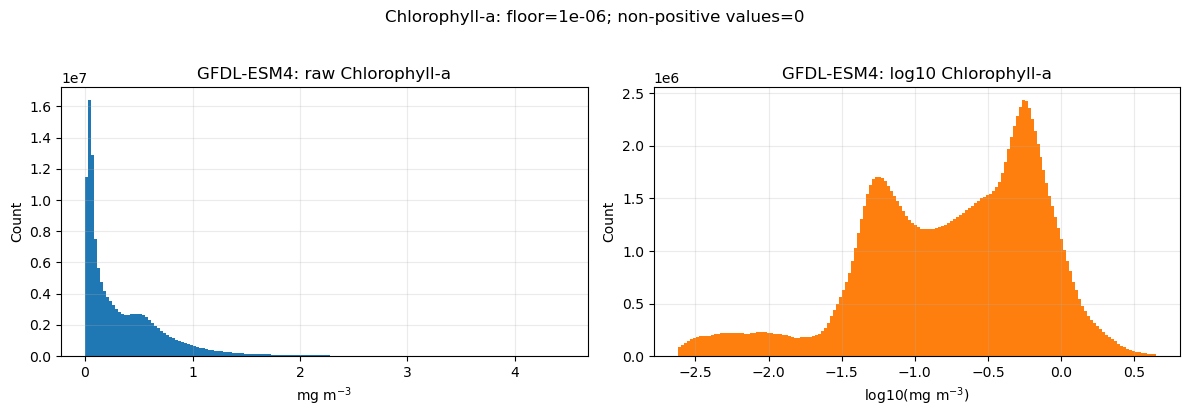


GFDL-ESM4: chlos anomaly comparison


raw_anomaly_p01    -5.016103e-01
raw_anomaly_p99     5.584794e-01
log_anomaly_p01    -4.160471e-01
log_anomaly_p99     4.006729e-01
log_anomaly_mean    1.678513e-10
log_anomaly_std     1.410361e-01
dtype: float64


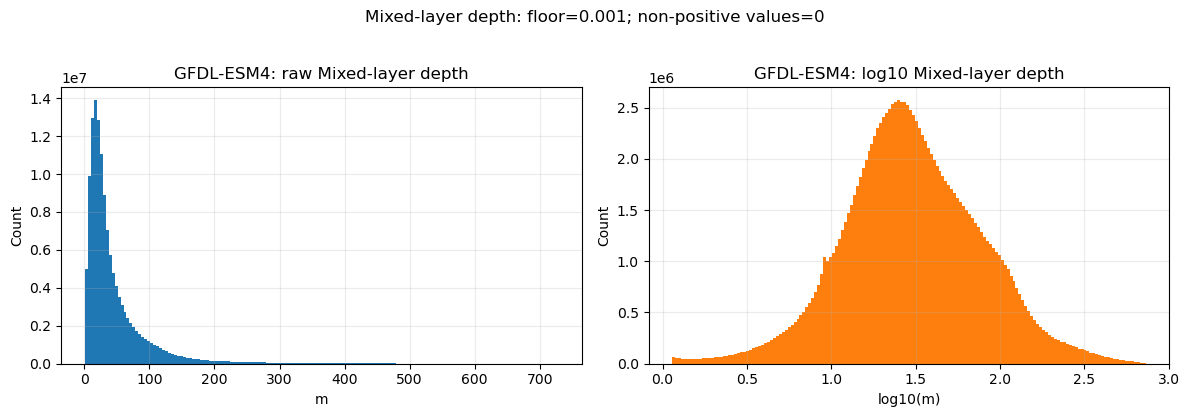


GFDL-ESM4: mlotst anomaly comparison


raw_anomaly_p01    -7.274593e+01
raw_anomaly_p99     7.556909e+01
log_anomaly_p01    -3.279565e-01
log_anomaly_p99     3.092624e-01
log_anomaly_mean    8.494820e-10
log_anomaly_std     1.198979e-01
dtype: float64

Loading UKESM1-0-LL
Dimensions: {'time': 3012, 'lat': 180, 'lon': 360}
Time range: 1850-01-16 to 2100-12-16


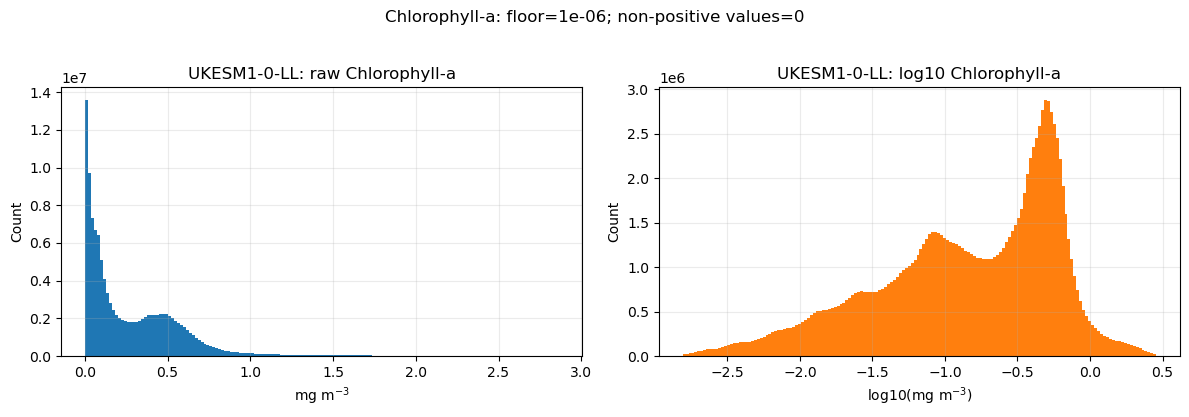


UKESM1-0-LL: chlos anomaly comparison


raw_anomaly_p01    -4.234579e-01
raw_anomaly_p99     4.695475e-01
log_anomaly_p01    -5.772925e-01
log_anomaly_p99     4.819013e-01
log_anomaly_mean    3.596159e-10
log_anomaly_std     1.729807e-01
dtype: float64


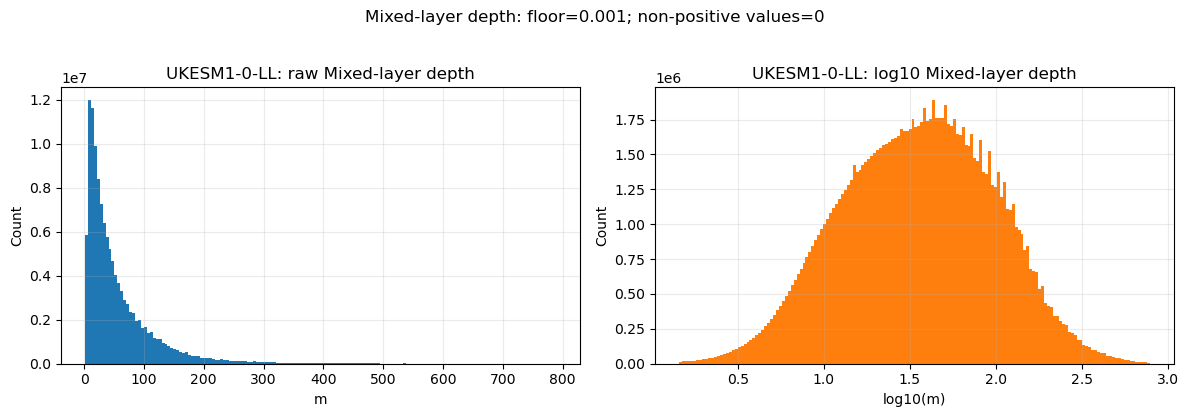


UKESM1-0-LL: mlotst anomaly comparison


raw_anomaly_p01    -7.440854e+01
raw_anomaly_p99     8.166112e+01
log_anomaly_p01    -3.933231e-01
log_anomaly_p99     3.749751e-01
log_anomaly_mean    1.094839e-09
log_anomaly_std     1.422906e-01
dtype: float64

CMIP6 summary


,source,variable,n_finite,n_nonpositive,fraction_nonpositive,raw_min,raw_p01,raw_p05,raw_median,raw_mean,...,raw_mean_median_ratio,log_p01,log_p05,log_median,log_mean,log_p95,log_p99,log_min,log_max,log_std
0,CESM2,chlos,107567556,0,0.000000,2.192610e-08,8.241857e-03,0.015386,0.099032,0.230498,...,2.327524,-2.083975,-1.812888,-1.004227,-0.968920,-0.052923,0.475526,-6.000000,1.452192,0.469695
1,CESM2,mlotst,107567556,429237,0.003990,0.000000e+00,3.971184e+00,14.208513,47.053040,64.238491,...,1.365236,0.818965,1.164196,1.674556,1.675242,2.218946,2.387581,-3.000000,3.441866,0.370485
2,CanESM5,chlos,124413672,0,0.000000,5.394937e-06,3.566819e-03,0.004046,0.113595,0.172421,...,1.517855,-2.447719,-2.392944,-0.944639,-1.150489,-0.375702,0.023673,-5.268014,1.477875,0.674607
3,CanESM5,mlotst,124597404,699074,0.005611,0.000000e+00,2.287612e+00,6.437799,37.027840,58.171000,...,1.571007,0.532537,0.831859,1.572308,1.553416,2.236063,2.522832,-3.000000,3.531220,0.453622
4,CanESM5-CanOE,chlos,124413672,0,0.000000,1.176778e-13,4.233912e-08,0.000022,0.157742,0.205764,...,1.304437,-6.000000,-4.658974,-0.802053,-1.370565,-0.177941,-0.045340,-6.000000,0.289141,1.408387
5,CanESM5-CanOE,mlotst,124597404,699074,0.005611,0.000000e+00,2.287612e+00,6.437799,37.027840,58.171000,...,1.571007,0.532537,0.831859,1.572308,1.553416,2.236063,2.522832,-3.000000,3.531220,0.453622
6,GFDL-ESM4,chlos,133009920,0,0.000000,4.581446e-16,3.527312e-03,0.011256,0.222777,0.376800,...,1.691376,-2.452556,-1.948631,-0.652129,-0.743906,0.062231,0.317464,-6.000000,1.383708,0.610101
7,GFDL-ESM4,mlotst,133009920,0,0.000000,8.556656e-01,2.586639e+00,6.599228,28.782104,48.539487,...,1.686447,0.412736,0.819493,1.459123,1.477579,2.158580,2.496583,-0.067696,3.692108,0.415307
8,UKESM1-0-LL,chlos,124383552,0,0.000000,1.304262e-07,3.345048e-03,0.009370,0.184891,0.297099,...,1.606885,-2.475598,-2.028272,-0.733084,-0.847417,-0.091350,0.211558,-6.000000,1.013570,0.623659
9,UKESM1-0-LL,mlotst,124494996,0,0.000000,9.522302e-01,3.368083e+00,6.472491,36.481796,59.178365,...,1.622134,0.527383,0.811071,1.562076,1.548079,2.246902,2.517002,-0.021258,3.679515,0.447356


In [5]:
rows = []

for model_name in CMIP6_MODELS:
    model_path = os.path.join(CMIP6_LOAD_DIR, f"{model_name}.zarr")
    if not os.path.exists(model_path):
        print(f"Skipping {model_name}: not found at {model_path}")
        continue

    print(f"\nLoading {model_name}")
    ds_model = xr.open_zarr(model_path, chunks=None)
    print("Dimensions:", dict(ds_model.sizes))
    print("Time range:", str(ds_model.time.values[0])[:10], "to", str(ds_model.time.values[-1])[:10])

    for variable, meta in VARIABLES.items():
        assert variable in ds_model, f"{model_name} missing {variable}"
        da = ds_model[variable].load()
        rows.append(distribution_summary(da, model_name, variable, meta["floor"]))
        plot_raw_log(da, model_name, variable, meta["floor"], meta["label"], meta["units"])
        print(f"\n{model_name}: {variable} anomaly comparison")
        print(pd.Series(monthly_climatology_summary(da, meta["floor"])))
        del da
        gc.collect()

    ds_model.close()
    del ds_model
    gc.collect()

cmip6_summary = pd.DataFrame(rows)
print("\nCMIP6 summary")
display(cmip6_summary)


satellite vs cmip

In [6]:
summary = pd.concat([satellite_summary, cmip6_summary], ignore_index=True)
summary = summary.sort_values(["variable", "source"]).reset_index(drop=True)

display(
    summary[[
        "source",
        "variable",
        "n_finite",
        "fraction_nonpositive",
        "raw_p01",
        "raw_median",
        "raw_mean",
        "raw_p99",
        "raw_mean_median_ratio",
        "log_p01",
        "log_median",
        "log_mean",
        "log_p99",
        "log_std",
    ]]
)

,source,variable,n_finite,fraction_nonpositive,raw_p01,raw_median,raw_mean,raw_p99,raw_mean_median_ratio,log_p01,log_median,log_mean,log_p99,log_std
0,CESM2,chlos,107567556,0.000000,8.241857e-03,0.099032,0.230498,2.988999,2.327524,-2.083975,-1.004227,-0.968920,0.475526,0.469695
1,CanESM5,chlos,124413672,0.000000,3.566819e-03,0.113595,0.172421,1.056022,1.517855,-2.447719,-0.944639,-1.150489,0.023673,0.674607
2,CanESM5-CanOE,chlos,124413672,0.000000,4.233912e-08,0.157742,0.205764,0.900866,1.304437,-6.000000,-0.802053,-1.370565,-0.045340,1.408387
3,GFDL-ESM4,chlos,133009920,0.000000,3.527312e-03,0.222777,0.376800,2.077134,1.691376,-2.452556,-0.652129,-0.743906,0.317464,0.610101
4,Satellite,chlos,22483817,0.000000,2.426151e-02,0.142795,0.305152,3.340888,2.136987,-1.615082,-0.845286,-0.813189,0.523862,0.425666
5,UKESM1-0-LL,chlos,124383552,0.000000,3.345048e-03,0.184891,0.297099,1.627638,1.606885,-2.475598,-0.733084,-0.847417,0.211558,0.623659
6,CESM2,mlotst,107567556,0.003990,3.971184e+00,47.053040,64.238491,243.926407,1.365236,0.818965,1.674556,1.675242,2.387581,0.370485
7,CanESM5,mlotst,124597404,0.005611,2.287612e+00,37.027840,58.171000,332.724850,1.571007,0.532537,1.572308,1.553416,2.522832,0.453622
8,CanESM5-CanOE,mlotst,124597404,0.005611,2.287612e+00,37.027840,58.171000,332.724850,1.571007,0.532537,1.572308,1.553416,2.522832,0.453622
9,GFDL-ESM4,mlotst,133009920,0.000000,2.586639e+00,28.782104,48.539487,313.749634,1.686447,0.412736,1.459123,1.477579,2.496583,0.415307


In [7]:
# Candidate floor diagnostics
CHL_FLOORS = [1e-8, 1e-7, 1e-6, 1e-5, 1e-4]

def floor_diagnostics(da, source, variable, floors):
    values = np.asarray(da.values, dtype=np.float64).ravel()
    values = values[np.isfinite(values)]

    rows = []

    for floor in floors:
        rows.append({
            "source": source,
            "variable": variable,
            "floor": floor,
            "floor_log10": np.log10(floor),
            "n_finite": values.size,
            "n_below_floor": int((values < floor).sum()),
            "fraction_below_floor": float((values < floor).mean()),
            "n_nonpositive": int((values <= 0).sum()),
            "fraction_nonpositive": float((values <= 0).mean()),
        })

    return pd.DataFrame(rows)

In [8]:
# Evaluate candidate Chl-a floors for every source

chl_floor_rows = []

chl_floor_sources = [
    ("Satellite", ds_sat),
]

for model_name, model_path in [
    ("CESM2", os.path.join(CMIP6_LOAD_DIR, "CESM2.zarr")),
    ("CanESM5", os.path.join(CMIP6_LOAD_DIR, "CanESM5.zarr")),
    ("CanESM5-CanOE", os.path.join(CMIP6_LOAD_DIR, "CanESM5-CanOE.zarr")),
    ("GFDL-ESM4", os.path.join(CMIP6_LOAD_DIR, "GFDL-ESM4.zarr")),
    ("UKESM1-0-LL", os.path.join(CMIP6_LOAD_DIR, "UKESM1-0-LL.zarr")),
]:
    if os.path.exists(model_path):
        ds_model = xr.open_zarr(model_path, chunks=None)
        chl_floor_sources.append((model_name, ds_model))

for source_name, ds_source in chl_floor_sources:
    print(f"Checking Chl-a floors for {source_name}")

    floor_table = floor_diagnostics(
        ds_source["chlos"],
        source_name,
        "chlos",
        CHL_FLOORS,
    )

    chl_floor_rows.append(floor_table)

    if source_name != "Satellite":
        ds_source.close()
        del ds_source
        gc.collect()

chl_floor_summary = pd.concat(
    chl_floor_rows,
    ignore_index=True,
)

display(chl_floor_summary)

Checking Chl-a floors for Satellite


Checking Chl-a floors for CESM2


Checking Chl-a floors for CanESM5


Checking Chl-a floors for CanESM5-CanOE


Checking Chl-a floors for GFDL-ESM4


Checking Chl-a floors for UKESM1-0-LL


,source,variable,floor,floor_log10,n_finite,n_below_floor,fraction_below_floor,n_nonpositive,fraction_nonpositive
0,Satellite,chlos,1.000000e-08,-8.0,22483817,0,0.000000e+00,0,0.0
1,Satellite,chlos,1.000000e-07,-7.0,22483817,0,0.000000e+00,0,0.0
2,Satellite,chlos,1.000000e-06,-6.0,22483817,0,0.000000e+00,0,0.0
3,Satellite,chlos,1.000000e-05,-5.0,22483817,0,0.000000e+00,0,0.0
4,Satellite,chlos,1.000000e-04,-4.0,22483817,0,0.000000e+00,0,0.0
5,CESM2,chlos,1.000000e-08,-8.0,107567556,0,0.000000e+00,0,0.0
6,CESM2,chlos,1.000000e-07,-7.0,107567556,335,3.114322e-06,0,0.0
7,CESM2,chlos,1.000000e-06,-6.0,107567556,338,3.142211e-06,0,0.0
8,CESM2,chlos,1.000000e-05,-5.0,107567556,354,3.290955e-06,0,0.0
9,CESM2,chlos,1.000000e-04,-4.0,107567556,436,4.053267e-06,0,0.0


In [9]:
chl_floor_summary_display = chl_floor_summary.copy()

chl_floor_summary_display["floor"] = (
    chl_floor_summary_display["floor"]
    .map(lambda x: f"{x:.0e}")
)

chl_floor_summary_display["fraction_below_floor_percent"] = (
    100 * chl_floor_summary_display["fraction_below_floor"]
)

chl_floor_summary_display = chl_floor_summary_display[
    [
        "source",
        "variable",
        "floor",
        "floor_log10",
        "n_below_floor",
        "fraction_below_floor_percent",
        "n_nonpositive",
        "fraction_nonpositive",
    ]
]

display(chl_floor_summary_display)

,source,variable,floor,floor_log10,n_below_floor,fraction_below_floor_percent,n_nonpositive,fraction_nonpositive
0,Satellite,chlos,1e-08,-8.0,0,0.000000,0,0.0
1,Satellite,chlos,1e-07,-7.0,0,0.000000,0,0.0
2,Satellite,chlos,1e-06,-6.0,0,0.000000,0,0.0
3,Satellite,chlos,1e-05,-5.0,0,0.000000,0,0.0
4,Satellite,chlos,1e-04,-4.0,0,0.000000,0,0.0
5,CESM2,chlos,1e-08,-8.0,0,0.000000,0,0.0
6,CESM2,chlos,1e-07,-7.0,335,0.000311,0,0.0
7,CESM2,chlos,1e-06,-6.0,338,0.000314,0,0.0
8,CESM2,chlos,1e-05,-5.0,354,0.000329,0,0.0
9,CESM2,chlos,1e-04,-4.0,436,0.000405,0,0.0


In [10]:
# Summarise the maximum fraction clipped across all sources
floor_max_clipping = (
    chl_floor_summary
    .groupby("floor", as_index=False)
    .agg(
        max_fraction_below_floor=("fraction_below_floor", "max"),
        mean_fraction_below_floor=("fraction_below_floor", "mean"),
        total_n_below_floor=("n_below_floor", "sum"),
    )
)

floor_max_clipping["max_fraction_percent"] = (
    100 * floor_max_clipping["max_fraction_below_floor"]
)

floor_max_clipping["mean_fraction_percent"] = (
    100 * floor_max_clipping["mean_fraction_below_floor"]
)

display(floor_max_clipping)

,floor,max_fraction_below_floor,mean_fraction_below_floor,total_n_below_floor,max_fraction_percent,mean_fraction_percent
0,1.000000e-08,0.005673,0.000946,706069,0.567287,0.094584
1,1.000000e-07,0.013397,0.002234,1667673,1.339735,0.223407
2,1.000000e-06,0.025401,0.004235,3161548,2.540076,0.423526
3,1.000000e-05,0.041598,0.006936,5177400,4.159753,0.693567
4,1.000000e-04,0.078293,0.013053,9744204,7.829312,1.305336


In [11]:
display(
    chl_floor_summary_display[
        chl_floor_summary_display["floor"].isin(["1e-08", "1e-07", "1e-06"])
    ]
)

,source,variable,floor,floor_log10,n_below_floor,fraction_below_floor_percent,n_nonpositive,fraction_nonpositive
0,Satellite,chlos,1e-08,-8.0,0,0.000000,0,0.0
1,Satellite,chlos,1e-07,-7.0,0,0.000000,0,0.0
2,Satellite,chlos,1e-06,-6.0,0,0.000000,0,0.0
5,CESM2,chlos,1e-08,-8.0,0,0.000000,0,0.0
6,CESM2,chlos,1e-07,-7.0,335,0.000311,0,0.0
7,CESM2,chlos,1e-06,-6.0,338,0.000314,0,0.0
10,CanESM5,chlos,1e-08,-8.0,0,0.000000,0,0.0
11,CanESM5,chlos,1e-07,-7.0,0,0.000000,0,0.0
12,CanESM5,chlos,1e-06,-6.0,0,0.000000,0,0.0
15,CanESM5-CanOE,chlos,1e-08,-8.0,705782,0.567287,0,0.0


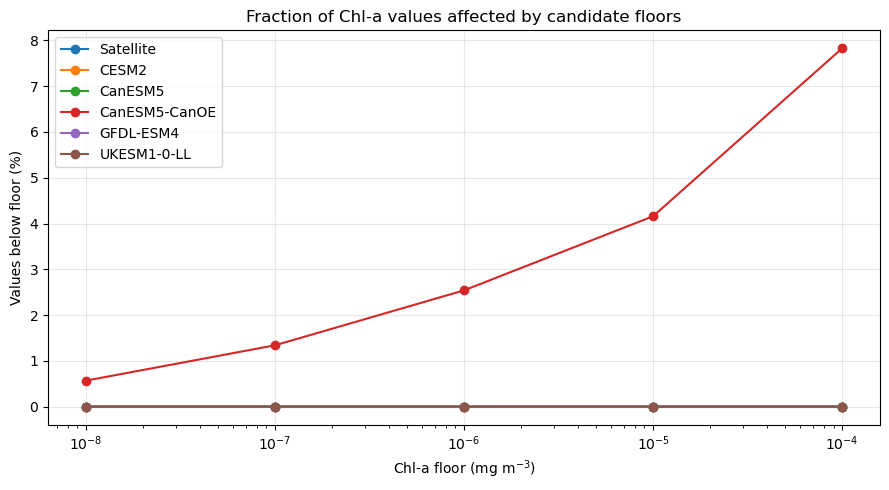

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

for source_name in chl_floor_summary["source"].unique():
    source_table = chl_floor_summary[
        chl_floor_summary["source"] == source_name
    ]

    ax.plot(
        source_table["floor"],
        100 * source_table["fraction_below_floor"],
        marker="o",
        label=source_name,
    )

ax.set_xscale("log")
ax.set_xlabel("Chl-a floor (mg m$^{-3}$)")
ax.set_ylabel("Values below floor (%)")
ax.set_title("Fraction of Chl-a values affected by candidate floors")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()